In [ ]:
# SETUP MANDIRI: menyiapkan folder, kode src/, dan dataset (SEED 1083) bila sesi baru
import os, sys, subprocess
ROOT = "/content/simuteh-2330511083"
for d in ["data/sintetis", "notebook", "src", "hasil", "laporan"]:
    os.makedirs(f"{ROOT}/{d}", exist_ok=True)
FILES = {'src/utils_cv.py': '"""utils_cv.py: fungsi bantu yang dipakai ulang sepanjang semester."""\nimport cv2\nimport numpy as np\nimport matplotlib.pyplot as plt\n\n\ndef baca(path):\n    """Membaca citra dan langsung memberi pesan jelas bila gagal."""\n    img = cv2.imread(path)\n    if img is None:\n        raise FileNotFoundError(f"Citra tidak ditemukan: {path}")\n    return img\n\n\ndef tampil(daftar, judul, baris=1, ukuran=(14, 4)):\n    """Menampilkan beberapa citra berdampingan. Citra 3 kanal dianggap BGR."""\n    kolom = int(np.ceil(len(daftar) / baris))\n    plt.figure(figsize=ukuran)\n    for i, (im, jd) in enumerate(zip(daftar, judul)):\n        plt.subplot(baris, kolom, i + 1)\n        if im.ndim == 3:\n            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))\n        else:\n            plt.imshow(im, cmap="gray", vmin=0, vmax=255)\n        plt.title(jd)\n        plt.axis("off")\n    plt.tight_layout()\n\n\ndef kontras_bercak(kanal, mask_daun, mask_bercak):\n    """KB = |rerata bercak - rerata daun sehat| / simpangan baku daun sehat."""\n    k = kanal.astype(np.float64)\n    sehat = (mask_daun > 0) & (mask_bercak == 0)\n    bercak = mask_bercak > 0\n    if bercak.sum() == 0:\n        return float("nan")\n    return abs(k[bercak].mean() - k[sehat].mean()) / (k[sehat].std() + 1e-6)\n\n\ndef statistik(gray):\n    """Ringkasan statistik intensitas untuk mendiagnosis mutu citra."""\n    return {"rerata": round(float(gray.mean()), 1),\n            "simpangan_baku": round(float(gray.std()), 1),\n            "min": int(gray.min()), "maks": int(gray.max()),\n            "persen_gelap": round(100 * float((gray < 50).mean()), 1),\n            "persen_terang": round(100 * float((gray > 205).mean()), 1)}', 'src/buat_dataset_sintetis.py': '"""\nbuat_dataset_sintetis.py\nMembangkitkan dataset citra sintetis daun teh untuk studi kasus SIMUTEH.\n"""\nimport os\nimport csv\nimport cv2\nimport numpy as np\n\nSEED = 1083          # 4 digit terakhir NIM 2330511083\nN_PER_KELAS = 20\nH, W = 480, 640\nKELAS = ["sehat", "ringan", "berat"]\nKONDISI = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]\nOUT = os.path.join("data", "sintetis")\nrng = np.random.default_rng(SEED)\n\n\ndef gambar_daun(img, mask):\n    """Menggambar satu helai daun berbentuk elips beserta tulang daunnya."""\n    cx = int(rng.integers(260, 380))\n    cy = int(rng.integers(200, 280))\n    ax = int(rng.integers(190, 240))\n    ay = int(rng.integers(95, 125))\n    sudut = float(rng.uniform(-25, 25))\n    hijau = np.array([rng.integers(35, 60), rng.integers(120, 150),\n                      rng.integers(45, 75)])  # BGR\n    cv2.ellipse(img, (cx, cy), (ax, ay), sudut, 0, 360, hijau.tolist(), -1)\n    cv2.ellipse(mask, (cx, cy), (ax, ay), sudut, 0, 360, 255, -1)\n    # tulang daun utama dan cabang\n    t = np.deg2rad(sudut)\n    p1 = (int(cx - ax * np.cos(t)), int(cy - ax * np.sin(t)))\n    p2 = (int(cx + ax * np.cos(t)), int(cy + ax * np.sin(t)))\n    tulang = (hijau * 1.35).clip(0, 255).tolist()\n    cv2.line(img, p1, p2, tulang, 3)\n    for k in np.linspace(-0.7, 0.7, 6):\n        bx, by = cx + k * ax * np.cos(t), cy + k * ax * np.sin(t)\n        for arah in (-1, 1):\n            ex = bx + 0.35 * ax * np.cos(t + arah * 1.0)\n            ey = by + 0.35 * ax * np.sin(t + arah * 1.0)\n            cv2.line(img, (int(bx), int(by)), (int(ex), int(ey)), tulang, 1)\n    return mask\n\n\ndef gambar_bercak(img, mask_daun, mask_bercak, kelas):\n    """Menambahkan bercak cacar daun (pucat kekuningan, tepi kecokelatan)."""\n    if kelas == "sehat":\n        return\n    n = int(rng.integers(1, 4)) if kelas == "ringan" else int(rng.integers(6, 13))\n    r_min, r_maks = (3, 7) if kelas == "ringan" else (5, 14)\n    ys, xs = np.where(mask_daun > 0)\n    for _ in range(n):\n        i = int(rng.integers(0, len(xs)))\n        r = int(rng.integers(r_min, r_maks + 1))\n        pusat = (int(xs[i]), int(ys[i]))\n        warna = [int(rng.integers(70, 100)), int(rng.integers(165, 190)),\n                 int(rng.integers(185, 210))]  # BGR pucat\n        cv2.circle(img, pusat, r + 2, (40, 80, 110), -1)  # tepi cokelat\n        cv2.circle(img, pusat, r, warna, -1)\n        cv2.circle(mask_bercak, pusat, r + 2, 255, -1)\n    mask_bercak &= mask_daun  # bercak hanya di daun\n\n\ndef ganggu_cahaya(img, kondisi):\n    """Mensimulasikan kondisi pemotretan di lapangan."""\n    f = img.astype(np.float32)\n    if kondisi == "gelap":\n        f = 255 * (f / 255) ** 2.0\n    elif kondisi == "terang":\n        f = 255 * (f / 255) ** 0.45\n    elif kondisi == "kontras_rendah":\n        f = 0.35 * f + 95\n    elif kondisi == "bayangan":\n        gx = np.linspace(1.15, 0.30, W, dtype=np.float32)  # separuh teduh\n        f = f * gx[None, :, None]\n    sigma = float(rng.uniform(6, 14))\n    f = f + rng.normal(0, sigma, f.shape)  # derau sensor\n    return np.clip(f, 0, 255).astype(np.uint8)\n\n\ndef main():\n    for sub in ["citra", "bersih", "mask_daun", "mask_bercak"]:\n        os.makedirs(os.path.join(OUT, sub), exist_ok=True)\n    baris = []\n    nomor = 0\n    for kelas in KELAS:\n        for j in range(N_PER_KELAS):\n            nomor += 1\n            latar = np.array([rng.integers(150, 190), rng.integers(170, 205),\n                              rng.integers(185, 215)])  # nampan anyaman\n            img = np.ones((H, W, 3), np.uint8) * latar.astype(np.uint8)\n            img = cv2.add(img, rng.integers(0, 12, (H, W, 3)).astype(np.uint8))\n            m_daun = np.zeros((H, W), np.uint8)\n            m_bercak = np.zeros((H, W), np.uint8)\n            gambar_daun(img, m_daun)\n            gambar_bercak(img, m_daun, m_bercak, kelas)\n            bersih = cv2.GaussianBlur(img, (3, 3), 0.8)\n            kondisi = KONDISI[j % len(KONDISI)]\n            citra = ganggu_cahaya(bersih, kondisi)\n            nama = f"teh_{nomor:03d}.png"\n            cv2.imwrite(os.path.join(OUT, "citra", nama), citra)\n            cv2.imwrite(os.path.join(OUT, "bersih", nama), bersih)\n            cv2.imwrite(os.path.join(OUT, "mask_daun", nama), m_daun)\n            cv2.imwrite(os.path.join(OUT, "mask_bercak", nama), m_bercak)\n            persen = 100 * (m_bercak > 0).sum() / max((m_daun > 0).sum(), 1)\n            baris.append([nama, kelas, kondisi, round(persen, 2)])\n    with open(os.path.join(OUT, "label.csv"), "w", newline="") as f:\n        w = csv.writer(f)\n        w.writerow(["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])\n        w.writerows(baris)\n    print(f"Selesai: {nomor} citra tersimpan di {OUT}")\n\n\nif __name__ == "__main__":\n    main()', 'src/praproses.py': '"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""\nimport json\nimport cv2\nimport numpy as np\n\nPARAM_BAWAAN = {\n    "lebar": 640,        # sampling: lebar citra kerja (piksel)\n    "gamma": 1.0,        # < 1 mencerahkan, > 1 menggelapkan\n    "clahe_clip": 2.0,   # 0 berarti CLAHE tidak dipakai\n    "clahe_tile": 8,\n    "penapis": "median", # "none", "rerata", "gaussian", "median"\n    "kernel": 3,\n    "sigma": 1.0,\n    "tajam_k": 0.0,      # 0 berarti tanpa penajaman\n}\n\ndef praproses(img_bgr, p=None):\n    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""\n    p = {**PARAM_BAWAAN, **(p or {})}\n\n    # 1. Ubah ukuran: lebar = p["lebar"], rasio aspek tetap, INTER_AREA\n    h, w = img_bgr.shape[:2]\n    tinggi = int(round(h * p["lebar"] / w))\n    img = cv2.resize(img_bgr, (p["lebar"], tinggi), interpolation=cv2.INTER_AREA)\n\n    # 2. Koreksi gamma lewat tabel LUT (hanya bila gamma != 1)\n    if p["gamma"] != 1:\n        lut = np.array([255 * (i / 255) ** p["gamma"] for i in range(256)])\n        img = cv2.LUT(img, lut.clip(0, 255).astype(np.uint8))\n\n    # 3. CLAHE hanya pada kanal V (HSV), lalu kembali ke BGR\n    if p["clahe_clip"] > 0:\n        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"],\n                                tileGridSize=(p["clahe_tile"], p["clahe_tile"]))\n        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)\n        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])\n        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)\n\n    # 4. Redam derau (ukuran kernel harus ganjil)\n    k = int(p["kernel"])\n    if p["penapis"] == "rerata":\n        img = cv2.blur(img, (k, k))\n    elif p["penapis"] == "gaussian":\n        img = cv2.GaussianBlur(img, (k, k), p["sigma"])\n    elif p["penapis"] == "median":\n        img = cv2.medianBlur(img, k)\n    # "none": tidak melakukan apa-apa\n\n    # 5. Unsharp masking: citra + k * (citra - blur)\n    if p["tajam_k"] > 0:\n        blur = cv2.GaussianBlur(img, (5, 5), 1.0)\n        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)\n\n    return img\n\ndef simpan_param(p, path="../hasil/param_praproses.json"):\n    with open(path, "w") as f:\n        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)'}
for p, t in FILES.items():
    if not os.path.exists(f"{ROOT}/{p}"):
        open(f"{ROOT}/{p}", "w").write(t)
os.chdir(ROOT)
if not os.path.exists("data/sintetis/label.csv"):
    print(subprocess.run([sys.executable, "src/buat_dataset_sintetis.py"], capture_output=True, text=True).stdout)
os.chdir(f"{ROOT}/notebook")


In [130]:
# === B4 ===
%cd /content/simuteh-2330511083/notebook
import sys, time
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

/content/simuteh-2330511083/notebook


In [131]:
def konvolusi(img, k):
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"), cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

for nm, k in {"rerata": np.ones((3, 3)) / 9,
              "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)}.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0
    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0
    beda = np.abs(a.astype(int) - b.astype(int)).max()
    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()
    print(f"{nm}: selisih manual vs filter2D={beda}, sejati vs filter2D={beda2}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=2.153 s, filter2D=0.00052 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=3.502 s, filter2D=0.00050 s


In [132]:
rng = np.random.default_rng(42)
def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)
def derau_sp(img, p):
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out
def ukur_waktu(f, x, ulang=20):
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)),
           "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}

baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d),
                      kontras_bercak(out, md, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)
print(tabel.to_string())
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

       derau   penapis  PSNR_dB  waktu_ms    KB
0   gauss_10     tanpa    28.11      0.00  3.39
1   gauss_10  rerata_3    36.90      0.13  5.46
2   gauss_10  rerata_5    37.74      0.16  5.62
3   gauss_10   gauss_5    37.74      0.28  5.61
4   gauss_10  median_3    35.51      0.10  5.39
5   gauss_10  median_5    38.39      0.78  6.24
6   gauss_10  median_9    38.62     13.97  7.10
7   gauss_20     tanpa    22.12      0.00  1.96
8   gauss_20  rerata_3    31.44      0.13  4.39
9   gauss_20  rerata_5    34.56      0.16  5.18
10  gauss_20   gauss_5    32.59      0.28  4.70
11  gauss_20  median_3    29.74      0.09  3.93
12  gauss_20  median_5    33.48      0.73  5.05
13  gauss_20  median_9    35.69     15.23  5.83
14  gauss_40     tanpa    16.57      0.00  0.98
15  gauss_40  rerata_3    25.98      0.13  2.70
16  gauss_40  rerata_5    29.84      0.16  3.80
17  gauss_40   gauss_5    27.18      0.29  3.03
18  gauss_40  median_3    23.83      0.10  2.26
19  gauss_40  median_5    27.84      0.7

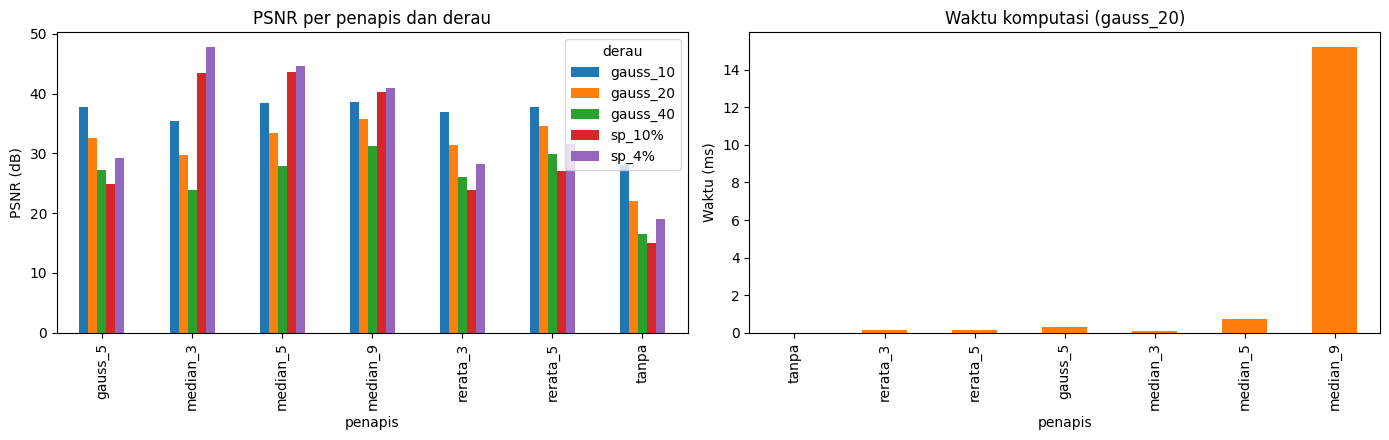

In [133]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
tabel.pivot(index="penapis", columns="derau", values="PSNR_dB").plot.bar(ax=ax[0])
ax[0].set_ylabel("PSNR (dB)"); ax[0].set_title("PSNR per penapis dan derau")
t = tabel[tabel.derau == "gauss_20"].set_index("penapis").waktu_ms
t.plot.bar(ax=ax[1], color="tab:orange")
ax[1].set_ylabel("Waktu (ms)"); ax[1].set_title("Waktu komputasi (gauss_20)")
plt.tight_layout(); plt.savefig("../hasil/b4_grafik_psnr_waktu.png"); plt.show()


           dI    KB
kernel             
1       27.33  4.34
3       27.64  4.45
5       26.50  4.32
9       19.76  3.69
15       8.09  2.15


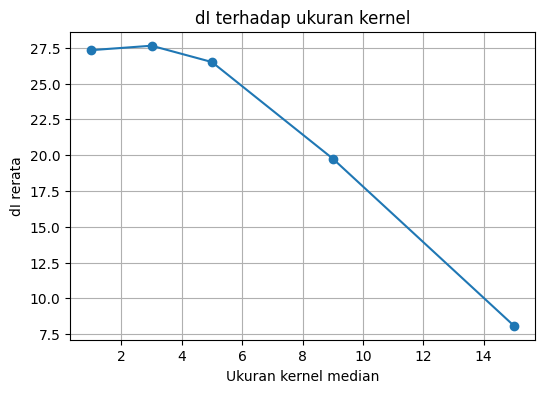

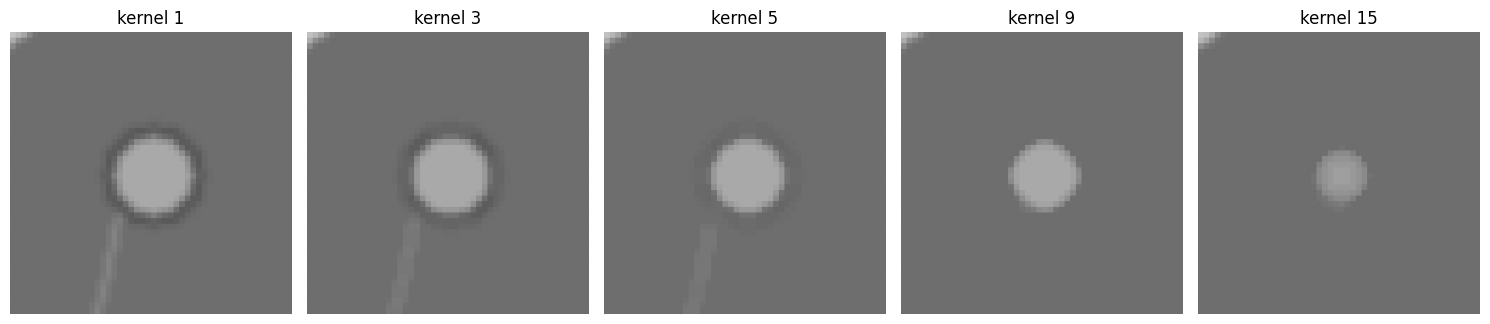

In [134]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2), kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
rm = hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2)
print(rm)
rm.to_csv("../hasil/b4_median_bercak.csv")

plt.figure(figsize=(6, 4)); plt.plot(rm.index, rm.dI, "o-")
plt.xlabel("Ukuran kernel median"); plt.ylabel("dI rerata")
plt.title("dI terhadap ukuran kernel"); plt.grid(True)
plt.savefig("../hasil/b4_dI_kernel.png"); plt.show()

# potongan bercak diperbesar: satu citra ringan, sekitar bercak pertama
nm = "teh_021.png"
g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
ys, xs = np.where(mb2 > 0); cy, cx = int(ys.mean()), int(xs.mean())
y0, y1, x0, x1 = max(cy-25, 0), cy+25, max(cx-25, 0), cx+25
potongan = [cv2.resize((g if k == 1 else cv2.medianBlur(g, k))[y0:y1, x0:x1], None,
            fx=6, fy=6, interpolation=cv2.INTER_NEAREST) for k in [1, 3, 5, 9, 15]]
tampil(potongan, [f"kernel {k}" for k in [1, 3, 5, 9, 15]], ukuran=(15, 3.5))
plt.savefig("../hasil/b4_potongan_bercak.png"); plt.show()

In [135]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy)); B = unsharp(redam(noisy))
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
          f"sigma_latar={A[latar].std():.1f} | redam->tajam "
          f"PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")

Gaussian: tajam->redam PSNR=30.41 sigma_latar=7.9 | redam->tajam PSNR=30.21 sigma_latar=8.2
Median: tajam->redam PSNR=30.17 sigma_latar=8.1 | redam->tajam PSNR=31.12 sigma_latar=7.2


In [136]:
PENAPIS_PILIHAN = "median_3"  # pilih dari: rerata_3, rerata_5, gauss_5, median_3, median_5, median_9
# alasan pilihan harus berasal dari Tabel 11 dan Sel 4.3 Anda

normal = [f"teh_{i:03d}.png" for i in range(1, 61, 5)]   # 12 citra: 001, 006, 011, ...
baris = []
for nm in normal:
    c = cv2.cvtColor(baca(f"../data/sintetis/citra/{nm}"), cv2.COLOR_BGR2GRAY)
    b0 = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    f = penapis[PENAPIS_PILIHAN]
    baris.append([nm, cv2.PSNR(b0, c), cv2.PSNR(b0, f(c))])
psnr12 = pd.DataFrame(baris, columns=["citra", "PSNR_sebelum", "PSNR_sesudah"]).round(2)
psnr12.loc[len(psnr12)] = ["rerata", psnr12.PSNR_sebelum.mean().round(2), psnr12.PSNR_sesudah.mean().round(2)]
print(psnr12.to_string())
psnr12.to_csv("../hasil/b4_psnr_12_normal.csv", index=False)

          citra  PSNR_sebelum  PSNR_sesudah
0   teh_001.png         32.23         39.41
1   teh_006.png         29.45         36.83
2   teh_011.png         30.76         38.07
3   teh_016.png         32.55         39.66
4   teh_021.png         30.04         37.36
5   teh_026.png         35.74         42.31
6   teh_031.png         35.19         41.97
7   teh_036.png         29.58         36.90
8   teh_041.png         32.45         39.48
9   teh_046.png         29.00         36.35
10  teh_051.png         29.39         36.70
11  teh_056.png         31.29         38.39
12       rerata         31.47         38.62


In [137]:
normal = [f"teh_{i:03d}.png" for i in range(1, 61, 5)]
for p in ["median_3", "median_5", "gauss_5"]:
    s = [cv2.PSNR(cv2.cvtColor(baca(f"../data/sintetis/bersih/{n}"), cv2.COLOR_BGR2GRAY),
                  penapis[p](cv2.cvtColor(baca(f"../data/sintetis/citra/{n}"), cv2.COLOR_BGR2GRAY)))
         for n in normal]
    print(p, "PSNR rerata 12 citra =", round(np.mean(s), 2))

median_3 PSNR rerata 12 citra = 38.62
median_5 PSNR rerata 12 citra = 41.04
gauss_5 PSNR rerata 12 citra = 40.27
